In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk
import textwrap

from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

In [2]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\gupta\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [4]:
stops = set(stopwords.words('english'))

In [5]:
stops = stops.union({'said', 'would', 'could', 'told',
                      'also', 'one', 'two', 'mr', 'new', 'year'})

In [6]:
df = pd.read_csv('BBC_Text_CLS.csv')
df.head()

,text,labels
0,Ad sales boost Time Warner profit\n\nQuarterly...,business
1,Dollar gains on Greenspan speech\n\nThe dollar...,business
2,Yukos unit buyer faces loan claim\n\nThe owner...,business
3,High fuel prices hit BA's profits\n\nBritish A...,business
4,Pernod takeover talk lifts Domecq\n\nShares in...,business


In [28]:
df.shape

(2225, 2)

In [9]:
vectorizer = CountVectorizer(stop_words=list(stops))

In [10]:
X = vectorizer.fit_transform(df['text'])

In [11]:
lda = LatentDirichletAllocation(n_components=10, random_state=42)

In [12]:
lda.fit(X)

LatentDirichletAllocation(random_state=42)

In [13]:
def plot_top_words(model, feature_names, n_top_words):

    fig, axes = plt.subplots(2, 5, figsize=(30, 15), sharex=True)
    axes = axes.flatten()

    for topic_idx, topic in enumerate(model.components_):
        top_features_ind = topic.argsort()[:-n_top_words - 1:-1]
        top_features = [feature_names[i] for i in top_features_ind]
        weights = topic[top_features_ind]

        ax = axes[topic_idx]
        ax.barh(top_features, weights, height=0.7)
        ax.set_title(f'Topic {topic_idx +1}', fontdict={'fontsize': 30})
        ax.invert_yaxis()
        ax.tick_params(axis='both', which='major', labelsize=20)
        for i in 'top right left'.split():
            ax.spines[i].set_visible(False)

    plt.subplots_adjust(top=0.90, bottom=0.05, wspace=0.90, hspace=0.3)
    plt.show()

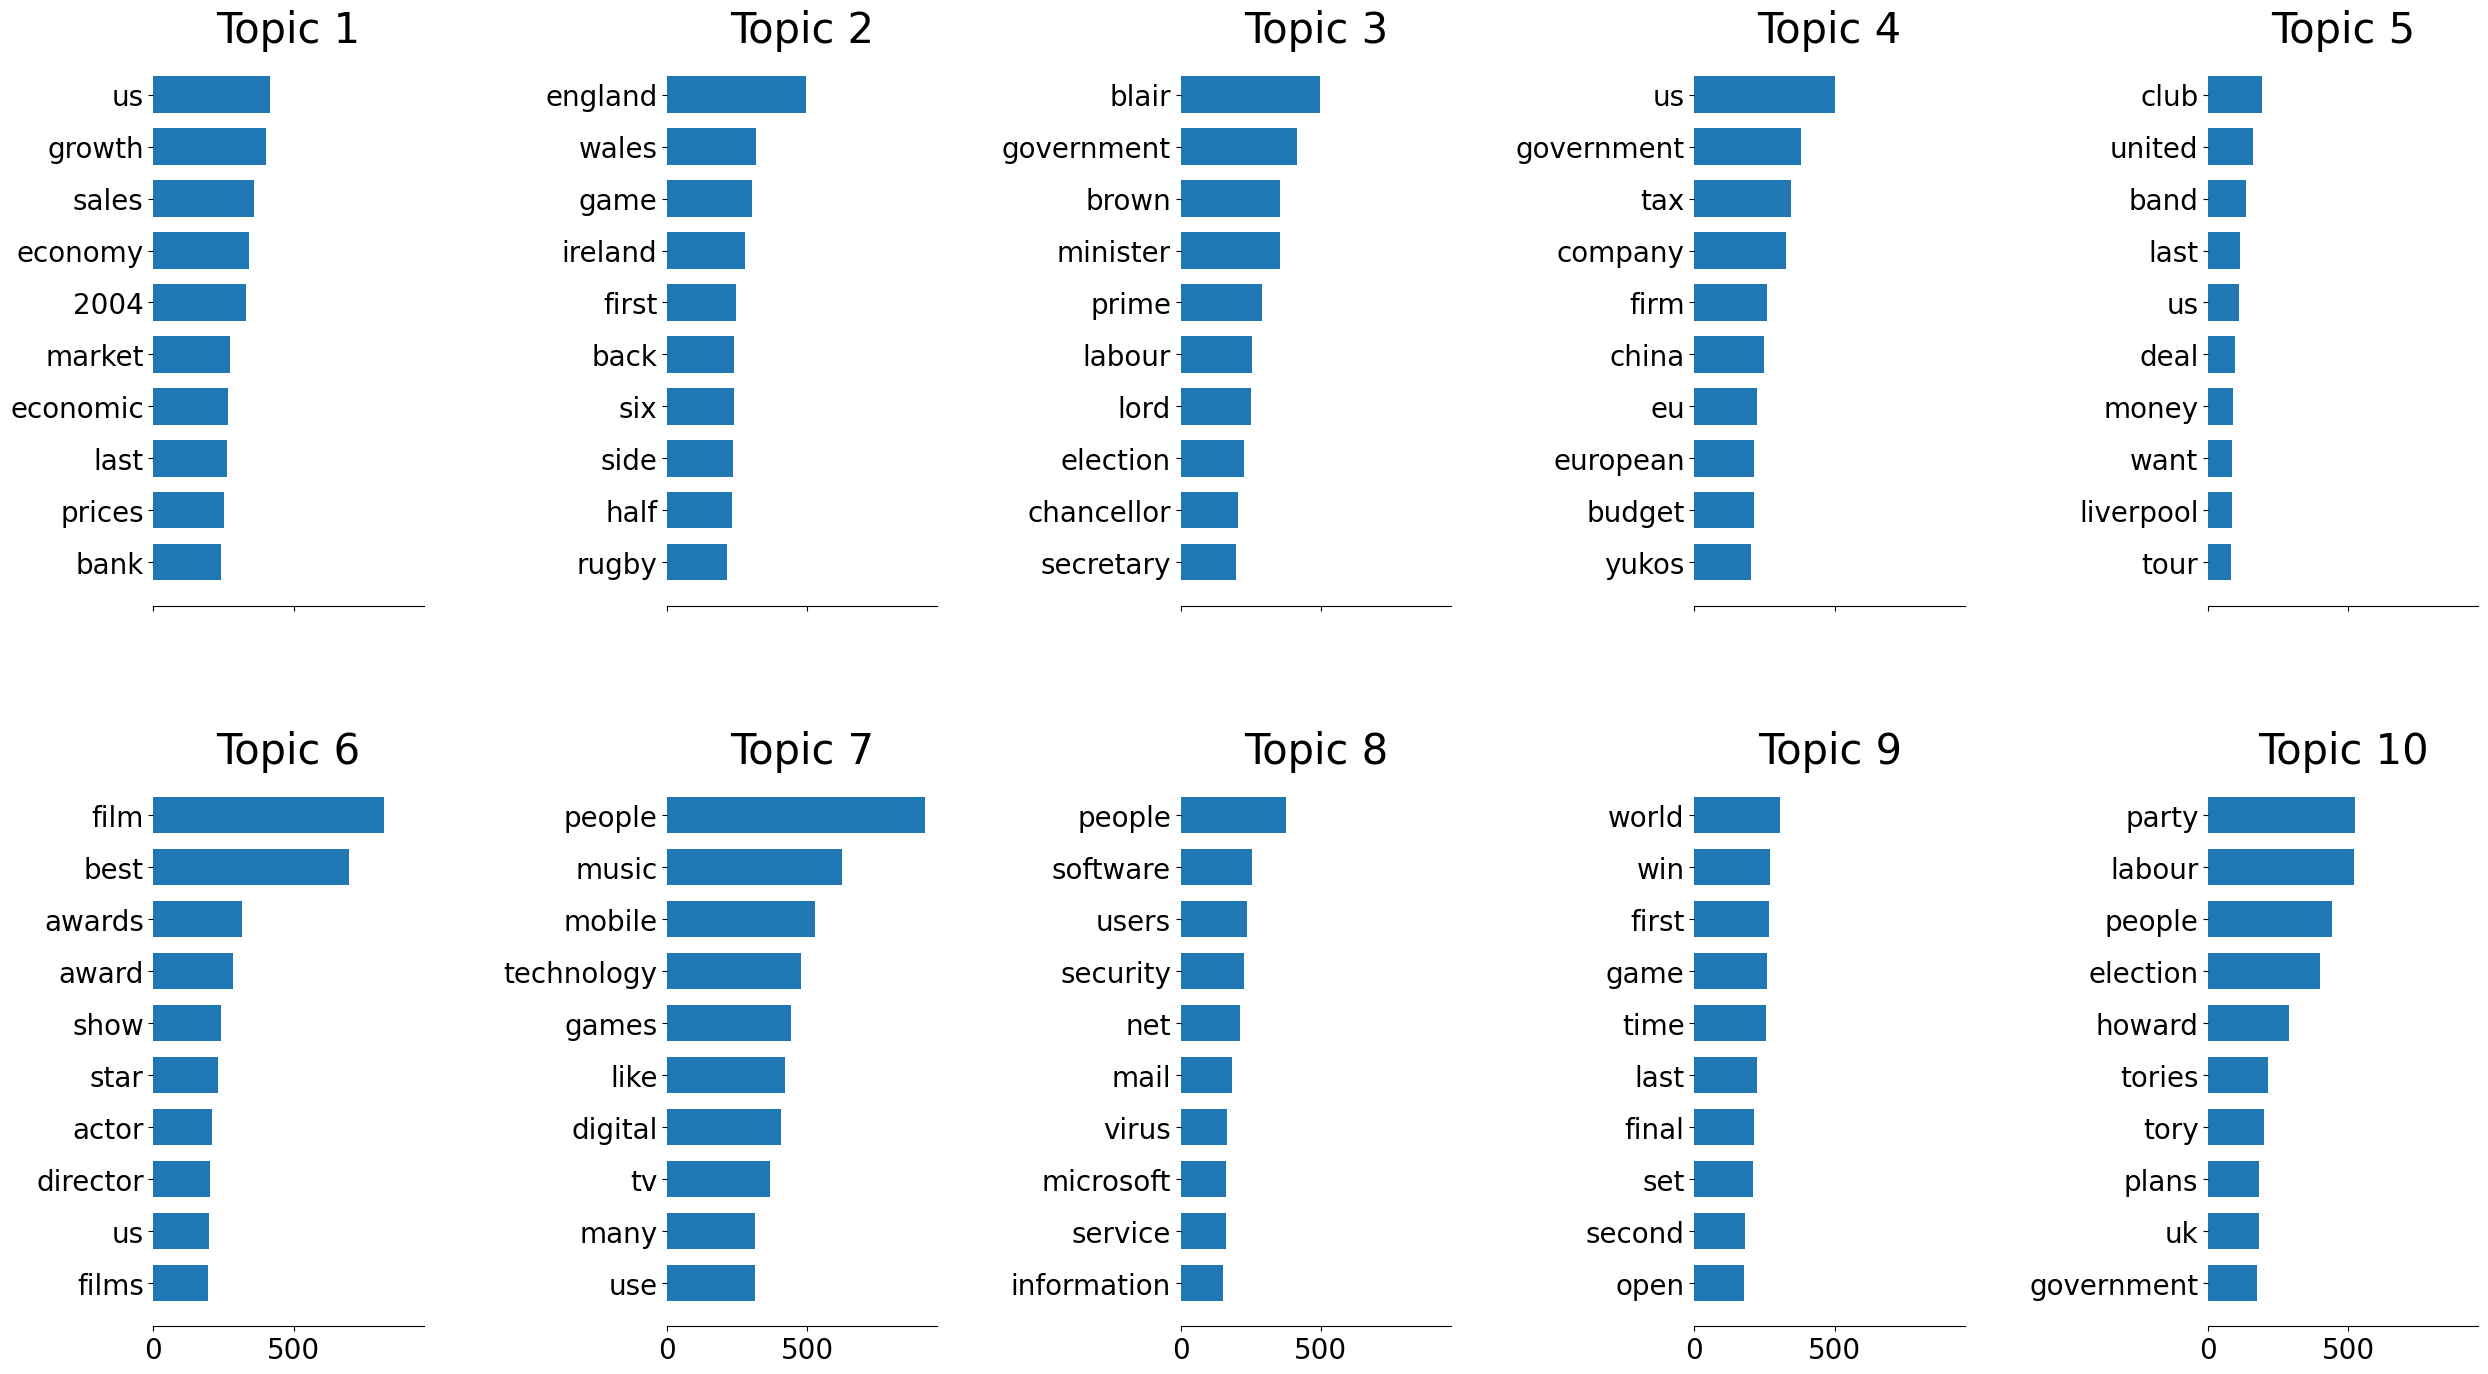

In [14]:
plot_top_words(lda, vectorizer.get_feature_names_out(), 10)

In [ ]:
Z = lda.transform(X)   # Returns [Documents x Topics] matrix

In [27]:
Z.shape

(2225, 10)

In [ ]:
lda.components_  # Returns [Topics x Words] matrix

array([[1.00036271e-01, 1.80307453e+02, 1.00028486e-01, ...,
        1.00000000e-01, 1.00000724e-01, 1.00000000e-01],
       [1.00022870e-01, 3.57764074e+00, 1.00000000e-01, ...,
        1.00000000e-01, 1.00001857e-01, 1.00000000e-01],
       [1.00013261e-01, 4.28355847e+01, 1.00489090e-01, ...,
        1.00000000e-01, 1.00000000e-01, 1.00000000e-01],
       ...,
       [2.19101054e+00, 1.44072601e+02, 1.00000000e-01, ...,
        1.00000000e-01, 1.00000381e-01, 1.00000000e-01],
       [1.80798004e+00, 2.30601409e+00, 1.00000000e-01, ...,
        1.00000000e-01, 1.00106706e-01, 1.00000000e-01],
       [1.00031028e-01, 9.36144185e+01, 1.00000000e-01, ...,
        1.09994082e+00, 4.09988165e+00, 1.00000000e-01]])

In [26]:
lda.components_.shape

(10, 29270)

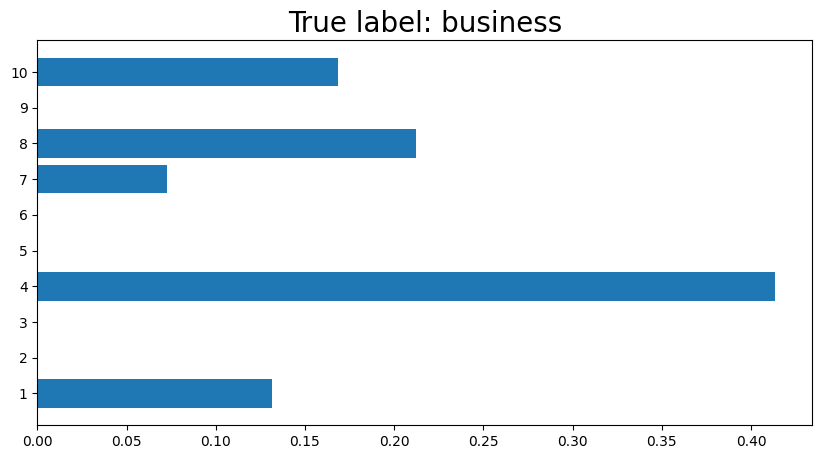

In [22]:
i = np.random.choice(len(df))
z = Z[i]
topics = np.arange(10) + 1

fig,ax = plt.subplots(figsize=(10,5))
ax.barh(topics, z)
ax.set_yticks(topics)
ax.set_title(f'True label: {df["labels"][i]}', fontsize=20)
plt.show()

In [23]:
def wrap(x):

    return textwrap.fill(x, replace_whitespace=False, fix_sentence_endings=True)

In [24]:
print(wrap(df.iloc[i]['text']))

Millions 'to lose textile jobs'

Millions of the world's poorest
textile trade workers will lose their jobs under new trade rules to be
introduced in the new year, a charity has warned.

The World Trade
Organisation (WTO) is to end its Multi-Fibre Agreement (MFA) on
midnight of 31 December.  Christian Aid condemned the move, saying it
would see almost a million jobs in Bangladesh alone being axed.
However, supporters of the change claim it will mean increased
efficiency and lower costs for Western consumers.

It will also see
more jobs created in India and China, advocates argue.  The WTO said
that many developing countries support the end of quotas and stressed
that funding was available to countries such as Bangladesh to help
them make the transition to a fully liberalised market.  "There will
be a period of adjustment required," said WTO spokesman Keith
Rockwell.  "Some countries will do better than others but there is no
one who is suggesting that no developing country will do well